# who drops out of substance use treatment in California

TEDS-D is the national discharge file for publicly funded substance use treatment. Every row is one treatment episode with what was known at admission (substance, route, referral source, prior episodes, living situation, employment, service setting) and how it ended (completed, dropped out, transferred, and so on).

Question: at admission, can you rank clients by how likely they are to drop out, and does a model beat the rule a program would already use, "outpatient clients with no prior treatment drop out most"? The point is early outreach, extra check-ins or case management for the clients most at risk, not a judgment about them. I use California only, since it is the state I would be working in and its admission fields are almost complete.

In [1]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

rng = np.random.default_rng(0)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## downloading the data

TEDS-D public use files from SAMHSA, one zip per discharge year. 2020 through 2023 are the years published under this naming pattern. The zips are 30 to 70 MB each and unzip to 250 MB each, except 2021 which is 2.2 GB because it ships with text labels instead of codes. Everything goes in data/, which is gitignored.

In [2]:
base = "https://www.samhsa.gov/data/system/files/media-puf-file/"
zips = {2020: "TEDS-D-2020-DS0001-bndl-data-csv_v1.zip",
        2021: "TEDS-D-2021-DS0001-bndl-data-csv_v1.zip",
        2022: "TEDS-D-2022-DS0001-bndl-data-csv_v1.zip",
        2023: "teds-d-2023-ds0001-bndl-data-csv_v1.zip"}

for year, z in zips.items():
    if os.path.exists(f"data/tedsd_puf_{year}.csv"):
        continue
    urllib.request.urlretrieve(base + z, f"data/{z}")
    with zipfile.ZipFile(f"data/{z}") as f:
        name = [n for n in f.namelist() if n.endswith(".csv")][0]
        f.extract(name, "data")
        os.rename(f"data/{name}", f"data/tedsd_puf_{year}.csv")

## loading

I only read the columns I use. The 2021 file has value labels where the other years have numeric codes, so the dict below (typed out from the 2023 codebook) turns the labels back into codes. The sex column is called GENDER before 2023 and SEX after.

In [3]:
labels = {
    "AGE": {"12-14 years old": 1, "15-17 years old": 2, "18-20 years old": 3, "21-24 years old": 4, "25-29 years old": 5, "30-34 years old": 6, "35-39 years old": 7, "40-44 years old": 8, "45-49 years old": 9, "50-54 years old": 10, "55-64 years old": 11, "65 years and older": 12},
    "SEX": {"male": 1, "female": 2, "missing/unknown/not collected/invalid": -9},
    "RACE": {"alaska native (aleut, eskimo)": 1, "american indian (other than alaska native)": 2, "asian or pacific islander": 3, "black or african american": 4, "white": 5, "asian": 6, "other single race": 7, "two or more races": 8, "native hawaiian or other pacific islander": 9, "missing/unknown/not collected/invalid": -9, "alaska native (aleut, eskimo, indian)": 1},
    "ETHNIC": {"puerto rican": 1, "mexican": 2, "cuban or other specific hispanic": 3, "not of hispanic or latino origin": 4, "hispanic or latino, specific origin not specified": 5, "missing/unknown/not collected/invalid": -9},
    "EDUC": {"grades 9 to 11": 2, "grade 12 (or ged)": 3, "1-3 years of college, university, or vocational school": 4, "4 years of college, university, ba/bs, some postgraduate study, or more": 5, "missing/unknown/not collected/invalid": -9, "less than one school grade, no schooling, nursery school, or kindergarten to grade 8": 1},
    "EMPLOY": {"full-time": 1, "part-time": 2, "unemployed": 3, "not in labor force": 4, "missing/unknown/not collected/invalid": -9},
    "LIVARAG": {"experiencing homelessness": 1, "dependent living": 2, "independent living": 3, "missing/unknown/not collected/invalid": -9, "homeless": 1},
    "PSOURCE": {"individual (includes self-referral)": 1, "alcohol/drug use care provider": 2, "other health care provider": 3, "school (educational)": 4, "employer/eap": 5, "other community referral": 6, "court/criminal justice referral/dui/dwi": 7, "missing/unknown/not collected/invalid": -9},
    "NOPRIOR": {"no prior treatment episode": 0, "one or more prior treatment episodes": 1, "missing/unknown/not collected/invalid": -9},
    "ARRESTS": {"none": 0, "once": 1, "two or more times": 2, "missing/unknown/not collected/invalid": -9},
    "VET": {"yes": 1, "no": 2, "missing/unknown/not collected/invalid": -9},
    "PREG": {"yes": 1, "no": 2, "missing/unknown/not collected/invalid": -9},
    "SERVICES": {"detox, 24-hour, hospital inpatient": 1, "detox, 24-hour, free-standing residential": 2, "rehab/residential, hospital (non-detox)": 3, "rehab/residential, short term (30 days or fewer)": 4, "rehab/residential, long term (more than 30 days)": 5, "ambulatory, intensive outpatient": 6, "ambulatory, non-intensive outpatient": 7, "ambulatory, detoxification": 8},
    "METHUSE": {"yes": 1, "no": 2, "missing/unknown/not collected/invalid": -9},
    "PSYPROB": {"yes": 1, "no": 2, "missing/unknown/not collected/invalid": -9},
    "DAYWAIT": {"0": 0, "1-7": 1, "8-14": 2, "15-30": 3, "31 or more": 4, "missing/unknown/not collected/invalid": -9},
    "SUB1": {"none": 1, "alcohol": 2, "cocaine/crack": 3, "marijuana/hashish": 4, "heroin": 5, "non-prescription methadone": 6, "other opiates and synthetics": 7, "pcp": 8, "hallucinogens": 9, "methamphetamine/speed": 10, "other amphetamines": 11, "other stimulants": 12, "benzodiazepines": 13, "other tranquilizers": 14, "barbiturates": 15, "other sedatives or hypnotics": 16, "inhalants": 17, "over-the-counter medications": 18, "other drugs": 19, "missing/unknown/not collected/invalid": -9},
    "SUB2": {"none": 1, "alcohol": 2, "cocaine/crack": 3, "marijuana/hashish": 4, "heroin": 5, "non-prescription methadone": 6, "other opiates and synthetics": 7, "pcp": 8, "hallucinogens": 9, "methamphetamine/speed": 10, "other amphetamines": 11, "other stimulants": 12, "benzodiazepines": 13, "other tranquilizers": 14, "barbiturates": 15, "other sedatives or hypnotics": 16, "inhalants": 17, "over-the-counter medications": 18, "other drugs": 19, "missing/unknown/not collected/invalid": -9},
    "ROUTE1": {"oral": 1, "smoking": 2, "inhalation": 3, "injection (intravenous, intramuscular, intradermal, or subcutaneous)": 4, "other": 5, "missing/unknown/not collected/invalid": -9},
    "FREQ1": {"no use in the past month": 1, "some use": 2, "daily use": 3, "missing/unknown/not collected/invalid": -9},
    "FRSTUSE1": {"11 years and under": 1, "12-14 years": 2, "15-17 years": 3, "18-20 years": 4, "21-24 years": 5, "25-29 years": 6, "30 years and older": 7, "missing/unknown/not collected/invalid": -9},
    "IDU": {"idu not reported": 0, "idu reported": 1, "no substances reported": -9},
    "ALCDRUG": {"none": 0, "alcohol only": 1, "other drugs only": 2, "alcohol and other drugs": 3},
    "FREQ_ATND_SELF_HELP": {"no attendance": 1, "1-3 times in the past month": 2, "4-7 times in the past month": 3, "8-30 times in the past month": 4, "some attendance, frequency is unknown": 5, "missing/unknown/not collected/invalid": -9},
    "REASON": {"treatment completed": 1, "dropped out of treatment": 2, "terminated by facility": 3, "transferred to another treatment program or facility": 4, "incarcerated": 5, "death": 6, "other": 7},
}

In [4]:
cols = list(labels) + ["DISYR", "STFIPS", "GENDER", "CBSA2010", "CBSA2020"]

def load(year):
    if year == 2021:
        d = pd.read_csv(f"data/tedsd_puf_{year}.csv", usecols=lambda c: c in cols, dtype=str, encoding="latin-1")
        d = d.rename(columns={"GENDER": "SEX"})
        d = d[d.STFIPS == "California"].copy()
        for c, m in labels.items():
            # blank cells in this file are the same as the -9 missing code
            d[c] = d[c].str.replace("\u2013", "-").str.strip().str.lower().map(m).fillna(-9)
        d["la_metro"] = d.CBSA2020.str.startswith("Los Angeles").fillna(False)
        d["STFIPS"] = 6
    else:
        d = pd.read_csv(f"data/tedsd_puf_{year}.csv", usecols=lambda c: c in cols)
        d = d.rename(columns={"GENDER": "SEX"})
        d = d[d.STFIPS == 6].copy()
        cbsa = "CBSA2010" if "CBSA2010" in d else "CBSA2020"
        d["la_metro"] = d[cbsa] == 31080
    d["DISYR"] = int(year)
    return d.drop(columns=[c for c in ["CBSA2010", "CBSA2020"] if c in d]).astype(int)

df = pd.concat([load(y) for y in zips], ignore_index=True)
print(len(df), "California discharges")
df.groupby("DISYR").size()

432128 California discharges


DISYR
2020    103161
2021    111210
2022    110347
2023    107410
dtype: int64

## target

Reason for discharge. California almost never uses the "terminated by facility" or "other" codes, so dropout is clean. Target A is dropped out or terminated by the facility. Target B is treatment completed. Transfers are neither, they count as not dropped out and not completed.

In [5]:
reason = {1: "completed", 2: "dropped out", 3: "terminated", 4: "transferred", 5: "incarcerated", 6: "death", 7: "other"}
(pd.crosstab(df.DISYR, df.REASON.map(reason), normalize="index") * 100).round(1)

REASON,completed,death,dropped out,incarcerated,other,terminated,transferred
DISYR,,,,,,,
2020,23.3,0.4,47.8,0.8,0.0,0.1,27.5
2021,25.3,1.8,43.5,0.8,0.0,0.0,28.5
2022,28.8,0.4,39.9,0.8,0.0,0.0,30.0
2023,29.9,0.3,38.3,0.7,0.0,0.1,30.6


In [6]:
df["dropout"] = df.REASON.isin([2, 3]).astype(int)
df["completed"] = (df.REASON == 1).astype(int)
df.groupby("DISYR")[["dropout", "completed"]].mean().round(3)

,dropout,completed
DISYR,,
2020,0.478,0.233
2021,0.436,0.253
2022,0.399,0.288
2023,0.383,0.299


## features

Everything known at admission. The four fields California does not collect (insurance, marital status, income source, DSM diagnosis) are not in the list. Three more are out because the 2021 file left them mostly blank (arrests 94% blank, secondary substance 45%, self-help attendance 9%) while the other years have them filled in. A first run with them in had the boosting model learn "arrests missing means 2021" and it fell apart on 2022. The assert makes sure nothing from the discharge side (reason, length of stay, anything ending in _D) gets in.

In [7]:
(df.groupby("DISYR")[["ARRESTS", "SUB2", "FREQ_ATND_SELF_HELP", "NOPRIOR", "PSYPROB"]].apply(lambda d: (d == -9).mean()) * 100).round(1)

,ARRESTS,SUB2,FREQ_ATND_SELF_HELP,NOPRIOR,PSYPROB
DISYR,,,,,
2020,0.1,1.7,2.2,0.2,0.4
2021,94.0,45.1,9.0,0.4,0.5
2022,0.1,3.1,1.2,1.6,1.6
2023,0.1,3.3,1.3,1.5,2.0


In [8]:
feat = ["AGE", "SEX", "RACE", "ETHNIC", "EDUC", "EMPLOY", "LIVARAG", "PSOURCE", "NOPRIOR",
        "VET", "PREG", "SERVICES", "METHUSE", "PSYPROB", "DAYWAIT", "SUB1", "ROUTE1", "FREQ1",
        "FRSTUSE1", "IDU", "ALCDRUG"]
for c in feat:
    assert not c.endswith("_D") and c not in ["REASON", "LOS", "SERVICES_D", "DISYR", "dropout", "completed"]

# every feature is a code, so one-hot everything (-9 missing becomes its own column)
X = pd.get_dummies(df[feat].astype(str), dtype=int)
print(X.shape)

(432128, 125)


## split by time

Train on earlier discharge years, test on the next one. Two folds: 2020 to 2021 predicting 2022, and 2020 to 2022 predicting 2023. The dropout rate fell from 48% in 2020 to 38% in 2023, so the models have to cope with drift.

## methods

- Baseline A: the program rule. Score 2 for outpatient settings plus 1 for no prior treatment, ties broken at random.
- Baseline B: service setting alone, scored by the training years' dropout rate for that setting.
- Logistic regression on the one-hot features.
- Gradient boosting (HistGradientBoostingClassifier) inside isotonic CalibratedClassifierCV, fit on training years only.

In [9]:
outpatient = df.SERVICES.isin([6, 7, 8]).astype(int)

def fit_predict(train, test, y):
    out = pd.DataFrame(index=test)
    out["rule"] = 2 * outpatient[test] + (df.NOPRIOR[test] == 0) + rng.uniform(0, 0.01, len(test))
    rate = df.loc[train].groupby("SERVICES")[y].mean()
    out["setting"] = df.SERVICES[test].map(rate).fillna(rate.mean()) + rng.uniform(0, 0.001, len(test))

    lr = LogisticRegression(max_iter=2000, C=0.5)
    lr.fit(X.loc[train], df.loc[train, y])
    out["logistic"] = lr.predict_proba(X.loc[test])[:, 1]

    hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                         min_samples_leaf=100, random_state=0)
    cal = CalibratedClassifierCV(hgb, method="isotonic", cv=3)
    cal.fit(X.loc[train], df.loc[train, y])
    out["boosting"] = cal.predict_proba(X.loc[test])[:, 1]
    return out

methods = ["rule", "setting", "logistic", "boosting"]
folds = {2022: df.index[df.DISYR <= 2021], 2023: df.index[df.DISYR <= 2022]}
scores = {}
for test_year, train in folds.items():
    test = df.index[df.DISYR == test_year]
    scores[test_year] = fit_predict(train, test, "dropout")
    print(test_year, "train", len(train), "test", len(test), "dropouts", df.dropout[test].sum())

2022 train 214371 test 110347 dropouts 44036


2023 train 324718 test 107410 dropouts 41172


## evaluation

Capture is the share of all dropouts in the test year that fall in the top 10% or 20% of clients by each method's score. That is the number that matters for outreach with a fixed caseload.

In [10]:
def top_flag(s, frac):
    k = int(np.ceil(len(s) * frac))
    return s.rank(ascending=False, method="first") <= k

def evaluate(score, y):
    r = {"PR-AUC": average_precision_score(y, score), "ROC-AUC": roc_auc_score(y, score)}
    for f in [0.1, 0.2]:
        top = top_flag(score, f)
        r[f"capture_{int(f*100)}"] = y[top].sum() / y.sum()
        r[f"precision_{int(f*100)}"] = y[top].mean()
    return r

rows = []
for test_year, s in scores.items():
    y = df.loc[s.index, "dropout"]
    for m in methods:
        rows.append({"test_year": test_year, "method": m, **evaluate(s[m], y)})
res = pd.DataFrame(rows)
res.round(3)

,test_year,method,PR-AUC,ROC-AUC,capture_10,precision_10,capture_20,precision_20
0,2022,rule,0.489,0.640,0.124,0.493,0.246,0.491
1,2022,setting,0.506,0.658,0.131,0.521,0.259,0.517
2,2022,logistic,0.547,0.689,0.151,0.602,0.296,0.591
3,2022,boosting,0.569,0.696,0.162,0.647,0.307,0.612
4,2023,rule,0.479,0.643,0.128,0.490,0.252,0.484
5,2023,setting,0.493,0.657,0.133,0.510,0.266,0.509
6,2023,logistic,0.533,0.686,0.156,0.597,0.300,0.575
7,2023,boosting,0.559,0.703,0.165,0.631,0.315,0.604


In [11]:
summary = res.groupby("method")[["PR-AUC", "ROC-AUC", "capture_10", "capture_20", "precision_10"]].mean().loc[methods]
summary.round(3)

,PR-AUC,ROC-AUC,capture_10,capture_20,precision_10
method,,,,,
rule,0.484,0.641,0.126,0.249,0.491
setting,0.500,0.658,0.132,0.262,0.516
logistic,0.540,0.687,0.153,0.298,0.600
boosting,0.564,0.700,0.163,0.311,0.639


## bootstrap CI on the gain over the rule

Resample clients with replacement inside each test year, recompute top 20% capture for the best model and the rule, take the difference, average over the two years.

In [12]:
best = summary["capture_20"].drop(["rule", "setting"]).idxmax()
print("best model:", best)

def capture(score, y, frac=0.2):
    return y[top_flag(score, frac)].sum() / y.sum()

def gain_once(idx_fn):
    g = []
    for test_year, s in scores.items():
        y = df.loc[s.index, "dropout"]
        i = idx_fn(len(s))
        g.append(capture(s[best].iloc[i], y.iloc[i]) - capture(s["rule"].iloc[i], y.iloc[i]))
    return np.mean(g) * 100

point = gain_once(lambda n: np.arange(n))
boots = np.array([gain_once(lambda n: rng.integers(0, n, n)) for _ in range(300)])
print(f"gain in top 20% capture, {best} over the rule: {point:.1f} points, 95% CI {np.percentile(boots, 2.5):.1f} to {np.percentile(boots, 97.5):.1f}")

best model: boosting


gain in top 20% capture, boosting over the rule: 6.2 points, 95% CI 5.9 to 6.5


## capture curve and calibration

Pooled over the two test years.

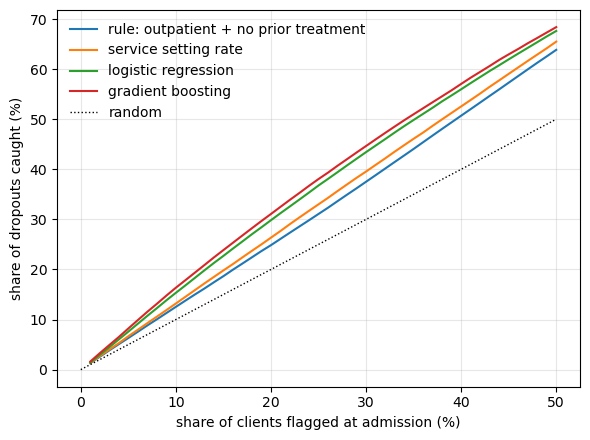

In [13]:
pool = pd.concat([s.assign(y=df.loc[s.index, "dropout"], year=t) for t, s in scores.items()])
fracs = np.linspace(0.01, 0.5, 50)
fig, ax = plt.subplots(figsize=(6, 4.5))
for m, lab in zip(methods, ["rule: outpatient + no prior treatment", "service setting rate", "logistic regression", "gradient boosting"]):
    order = pool[m].rank(ascending=False, method="first")
    ax.plot(fracs * 100, [pool.y[order <= np.ceil(len(pool) * f)].sum() / pool.y.sum() * 100 for f in fracs], label=lab)
ax.plot([0, 50], [0, 50], "k:", lw=1, label="random")
ax.set_xlabel("share of clients flagged at admission (%)")
ax.set_ylabel("share of dropouts caught (%)")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/capture_curve.png", dpi=150)

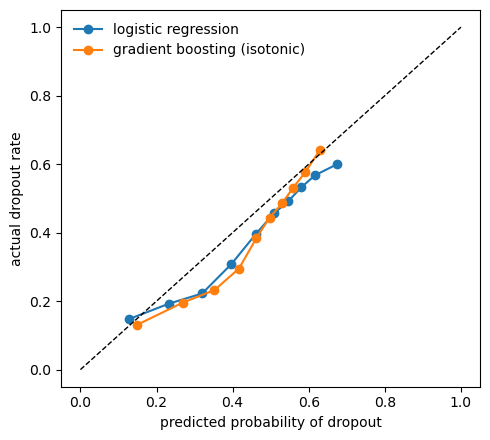

In [14]:
fig, ax = plt.subplots(figsize=(5, 4.5))
for m, lab in zip(["logistic", "boosting"], ["logistic regression", "gradient boosting (isotonic)"]):
    frac_pos, mean_pred = calibration_curve(pool.y, pool[m], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=lab)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("predicted probability of dropout")
ax.set_ylabel("actual dropout rate")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=150)

## does the model know more than the setting

Service setting is the strongest single thing here, outpatient clients drop out at twice the rate of residential clients. A model that only relearns that is not useful to a program that already knows it. So the check below scores clients within each setting: AUC within setting, and capture when the top 20% is picked separately inside each setting.

In [15]:
setting = {2: "detox, residential", 4: "residential, short", 5: "residential, long", 6: "intensive outpatient", 7: "outpatient"}
pool["setting_name"] = df.SERVICES[pool.index].map(setting)
rows = []
for name, g in pool.dropna(subset=["setting_name"]).groupby("setting_name"):
    if g.y.sum() < 200:
        continue
    rows.append({"setting": name, "clients": len(g), "dropout_rate": g.y.mean(),
                 "auc_rule": roc_auc_score(g.y, g.rule), "auc_logistic": roc_auc_score(g.y, g.logistic),
                 "auc_boosting": roc_auc_score(g.y, g.boosting),
                 "capture20_rule": capture(g.rule, g.y), "capture20_boosting": capture(g.boosting, g.y)})
pd.DataFrame(rows).round(3)

,setting,clients,dropout_rate,auc_rule,auc_logistic,auc_boosting,capture20_rule,capture20_boosting
0,"detox, residential",23912,0.158,0.479,0.612,0.636,0.175,0.324
1,intensive outpatient,21212,0.453,0.491,0.599,0.603,0.194,0.259
2,outpatient,115606,0.512,0.484,0.578,0.606,0.194,0.246
3,"residential, long",54247,0.217,0.497,0.565,0.585,0.197,0.272
4,"residential, short",2228,0.273,0.489,0.484,0.532,0.184,0.222


## subgroups

Living arrangement at admission, LA metro vs the rest of California, and race. AUC for the rule and for boosting, plus the share of each group that lands in boosting's top 20%.

In [16]:
living = {1: "homeless", 2: "dependent living", 3: "independent living"}
race = {3: "Asian or Pacific Islander", 4: "Black", 5: "White", 6: "Asian", 7: "other single race", 8: "two or more races", 9: "Native Hawaiian or Pacific Islander", 2: "American Indian"}
pool["living"] = df.LIVARAG[pool.index].map(living)
pool["race"] = df.RACE[pool.index].map(race)
pool["hispanic"] = np.where(df.ETHNIC[pool.index].isin([1, 2, 3, 5]), "Hispanic", "not Hispanic")
pool["area"] = np.where(df.la_metro[pool.index] == 1, "LA metro", "rest of CA")
pool["flagged"] = top_flag(pool.boosting, 0.2)

rows = []
for col in ["living", "area", "hispanic", "race"]:
    for name, g in pool.dropna(subset=[col]).groupby(col):
        if g.y.sum() < 300:
            continue
        rows.append({"group": f"{col}: {name}", "clients": len(g), "dropout_rate": g.y.mean(),
                     "auc_rule": roc_auc_score(g.y, g.rule), "auc_boosting": roc_auc_score(g.y, g.boosting),
                     "share_flagged": g.flagged.mean(), "precision_flagged": g.y[g.flagged].mean()})
pd.DataFrame(rows).round(3)

,group,clients,dropout_rate,auc_rule,auc_boosting,share_flagged,precision_flagged
0,living: dependent living,50240,0.408,0.603,0.662,0.207,0.570
1,living: homeless,72511,0.306,0.638,0.689,0.107,0.598
2,living: independent living,94751,0.448,0.613,0.689,0.268,0.627
3,area: LA metro,55259,0.349,0.581,0.628,0.185,0.504
4,area: rest of CA,162498,0.406,0.659,0.719,0.205,0.640
5,hispanic: Hispanic,93912,0.398,0.635,0.690,0.211,0.607
6,hispanic: not Hispanic,123845,0.386,0.646,0.706,0.192,0.609
7,race: American Indian,3452,0.378,0.662,0.721,0.172,0.580
8,race: Asian,3382,0.398,0.636,0.684,0.190,0.632
9,race: Black,24163,0.362,0.635,0.680,0.128,0.558


## completion target

Same methods, target is treatment completed. The rule is flipped (residential plus prior treatment) since it is now scoring a good outcome.

In [17]:
rows = []
for test_year, train in folds.items():
    test = df.index[df.DISYR == test_year]
    s = fit_predict(train, test, "completed")
    s["rule"] = 2 * (1 - outpatient[test]) + (df.NOPRIOR[test] == 1) + rng.uniform(0, 0.01, len(test))
    y = df.loc[test, "completed"]
    for m in methods:
        rows.append({"method": m, **evaluate(s[m], y)})
pd.DataFrame(rows).groupby("method").mean().loc[methods].round(3)

,PR-AUC,ROC-AUC,capture_10,precision_10,capture_20,precision_20
method,,,,,,
rule,0.379,0.610,0.143,0.420,0.286,0.419
setting,0.418,0.640,0.165,0.485,0.328,0.481
logistic,0.485,0.725,0.192,0.564,0.354,0.520
boosting,0.502,0.739,0.199,0.583,0.365,0.537


## sensitivity: leaving transfers out

30% of California episodes end in a transfer, which I counted as not dropping out. Some of those are probably dropouts that got routed elsewhere, and some dropouts are probably unrecorded transfers. So the same models are refit and scored with transferred episodes removed from both the training and the test years. The question is only whether the gain over the rule holds.

In [18]:
keep = df.index[df.REASON != 4]
rows, gains = [], []
for test_year, train in folds.items():
    tr = train.intersection(keep)
    te = df.index[df.DISYR == test_year].intersection(keep)
    s = fit_predict(tr, te, "dropout")
    y = df.loc[te, "dropout"]
    for m in methods:
        rows.append({"test_year": test_year, "method": m, **evaluate(s[m], y)})
    gains.append(capture(s["boosting"], y) - capture(s["rule"], y))
    print(test_year, "episodes without transfers", len(te), "dropout rate", round(y.mean(), 3))
sens = pd.DataFrame(rows).groupby("method")[["PR-AUC", "ROC-AUC", "capture_10", "capture_20"]].mean().loc[methods]
print(f"gain in top 20% capture, boosting over the rule, no transfers: {np.mean(gains) * 100:.1f} points")
sens.round(3)

2022 episodes without transfers 77220 dropout rate 0.57


2023 episodes without transfers 74507 dropout rate 0.553
gain in top 20% capture, boosting over the rule, no transfers: 7.1 points


,PR-AUC,ROC-AUC,capture_10,capture_20
method,,,,
rule,0.660,0.655,0.119,0.239
setting,0.677,0.670,0.123,0.248
logistic,0.789,0.749,0.160,0.308
boosting,0.798,0.758,0.162,0.310
